              mean_fare
service_type           
InDrive          573.51
Careem           544.98
Rickshaw         486.64
Uber             486.13
city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64
City with the most trips: Islamabad
Average distance per trip (km): 9.61
        count  mean  median
gender                     
Female     51  2.82     3.0
Male       49  3.33     4.0


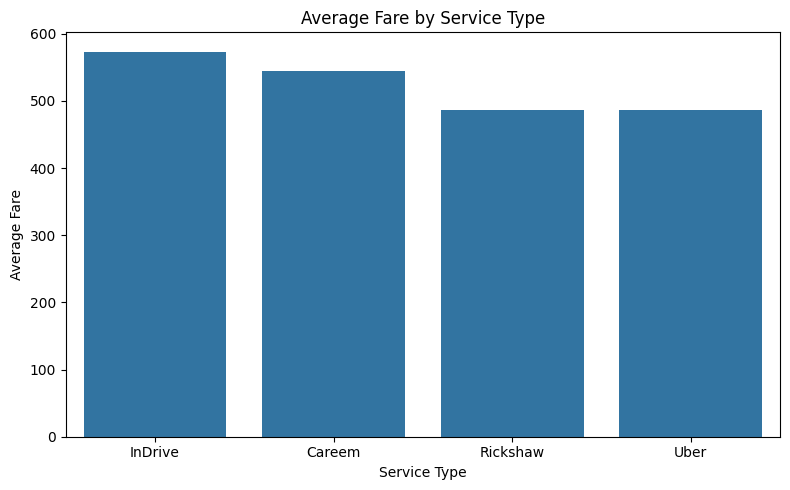

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

hailing = pd.read_csv("ride_hailing_dataset.csv")

fare_means = (
    hailing
    .groupby("service_type")["fare"]
    .agg(mean_fare="mean")
    .round(2)
    .sort_values("mean_fare", ascending=False)
)
print(fare_means)

city_trip_counts = hailing["city"].value_counts()
print(city_trip_counts)
print("City with the most trips:", city_trip_counts.index[0])

avg_distance = hailing["distance_km"].agg("mean")
print("Average distance per trip (km):", round(avg_distance, 2))

rating_summary = (
    hailing
    .groupby("gender")["trip_rating"]
    .agg(["count", "mean", "median"])
    .round(2)
)
print(rating_summary)

fare_by_service = (
    hailing
    .groupby("service_type", as_index=False)["fare"]
    .mean()
    .sort_values("fare", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=fare_by_service, x="service_type", y="fare", ax=ax)
ax.set_title("Average Fare by Service Type")
ax.set_xlabel("Service Type")
ax.set_ylabel("Average Fare")
fig.tight_layout()
plt.show()